# **Sesión 4:** Procesamiento de imagenes y extracción de características

## Instalación de paquetes necesarios

In [2]:
# ! pip install tqdm scikit-learn pandas openpyxl

In [3]:
# import sys
# !{sys.executable} -m pip install tqdm scikit-learn pandas openpyxl  # Solamente si lo anterior no funciona ejecutar esta opción

## **Librerías**

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from utils import *
from bow import BoW
from dataset import Dataset
from image_classifier import ImageClassifier
import time
from tqdm import tqdm
import sys
import pickle
import os

In [5]:
# Nos definimos estas funciones auxiliares que nos facilitará algunas tareas más adelante
from rpds import List

def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name, img)  # Mostramos la imagen, poniendole el nombre correspondiente a la ventana desplegada
    cv2.waitKey(0)  # Ponemos una tecla para eliminar la ventana y pasar a la siguiente imagen o terminar la visualización
    cv2.destroyAllWindows()

def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder, img_name)  # creamos el path donde vamos a guardar la imagen
    os.makedirs(output_folder, exist_ok=True)
    cv2.imwrite(img_path, img)  # guardamos la imagen en su correspondiente ubicación

# **Apartado B**: Detección de puntos de interés y bolsa de palabras

## **B1: Detección de puntos de interés**

### **Tarea B.1**: Generar función de filtro gaussiano

Se generará a partir de la imagen de la carpeta `data/partB` las imágenes con el filtrado gaussiano. Para ello se empleará la función `generateGaussianImages()` que tiene que desarrollar empleando la función [`cv2.GaussianBlur()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gae8bdcd9154ed5ca3cbc1766d960f45c1). Es recomendble visualizar los resultados para comprobar el funcionamiento. Para ello convierta los datos de la imagen a visualizar a `np.uint8`

In [6]:
def generateGaussianImages(image, sigmas):
    """Generate the gaussian images using the base image and the sigmas given

    Args:
        image (np.array[np.float32]): Base image to blur
        sigmas (List[np.float32]): Sigmas for blurring the image 

    Returns:
        List[np.array[np.float32]: List of blurred images
    """
    gaussian_images = []

    # TODO: Generate the list of blurred images using cv2.GaussianBlur()
    for sigma in sigmas:
        
        k = max(3, 2*round(3*sigma + 1))  # en caso de no tener el tamaño del kernel, lo sacamos en función de la sigma del kernel
        if k % 2 == 0:
            k += 1  # Nos aseguramos de que sea un valor impar
    
        blurred_image = cv2.GaussianBlur(image, (k, k), sigmaX=float(sigma), sigmaY=float(sigma))
        gaussian_images.append(blurred_image)
    
    return gaussian_images
    

### **Tarea B.2**: Generación de espacio de escalas con imágenes gaussianas

Empleando la función anterior, complete la siguiente celda para generar las imágenes gaussianas

In [7]:
# Cargamos las imágenes correspondientes al apartado A de la práctica
import glob

imgs_gen_path = '../data/partB/*.jpg' # Patrón que cumplen todos los paths de los archivos de imágenes de la carpeta data/partB
imgs_path = sorted(glob.glob(imgs_gen_path))  # Cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
imgs_path

['../data/partB\\0.jpg',
 '../data/partB\\0_rot.jpg',
 '../data/partB\\estudio.jpg',
 '../data/partB\\paisaje_pregunta_b1_1.jpg']

In [8]:
#TODO: Load the image in grayscale

# Cargamos la imagen original (la no rotada) y la convertimos a escala de grises
image = cv2.imread(imgs_path[0], cv2.IMREAD_GRAYSCALE)
image = image.astype(np.float32)  # Convertimos la imagen a float32

# Number of diference of gaussians to generate (minimum 3)

# TODO: Adjust this number to make sure keypoints are generated
intervals = 5  # Elegimos usar 5+1=6 gaussianas distintas para detectar los máximos y mínimos 

# Initial sigma
sigma = 1.6  # Sigma inicial de las 6 que va a haber en total

# We get the necessary sigmas from the given method generateGaussianSigmas()

# Función perteneciente a utils.py que nos permite generar una lista de sigmas, kernels gaussianos para aplicar el blur a la imagen
sigmas = sorted(generateGaussianSigmas(sigma, intervals))  #  recibe la sigma inicial y el número de diferencias de gaussianas que queremos generar

#TODO: Generate the gaussian images
gaussian_images = generateGaussianImages(image, sigmas)


In [9]:
print(len(gaussian_images))
print(len(sigmas))
print(sigmas)

6
6
[0.9044004929115251, 1.0388833584659771, 1.1933636049036624, 1.3708148098661692, 1.5746527170988414, 1.6]


In [10]:
for i, img in enumerate(gaussian_images):
    show_image(img.astype(np.uint8), img_name=f"Gaussian Image {i}")
    save_path = f"../output/partB/gaussian_image_{i}.jpg"
    write_image("../output/partB", f"gaussian_image_{i}.jpg", img.astype(np.uint8))

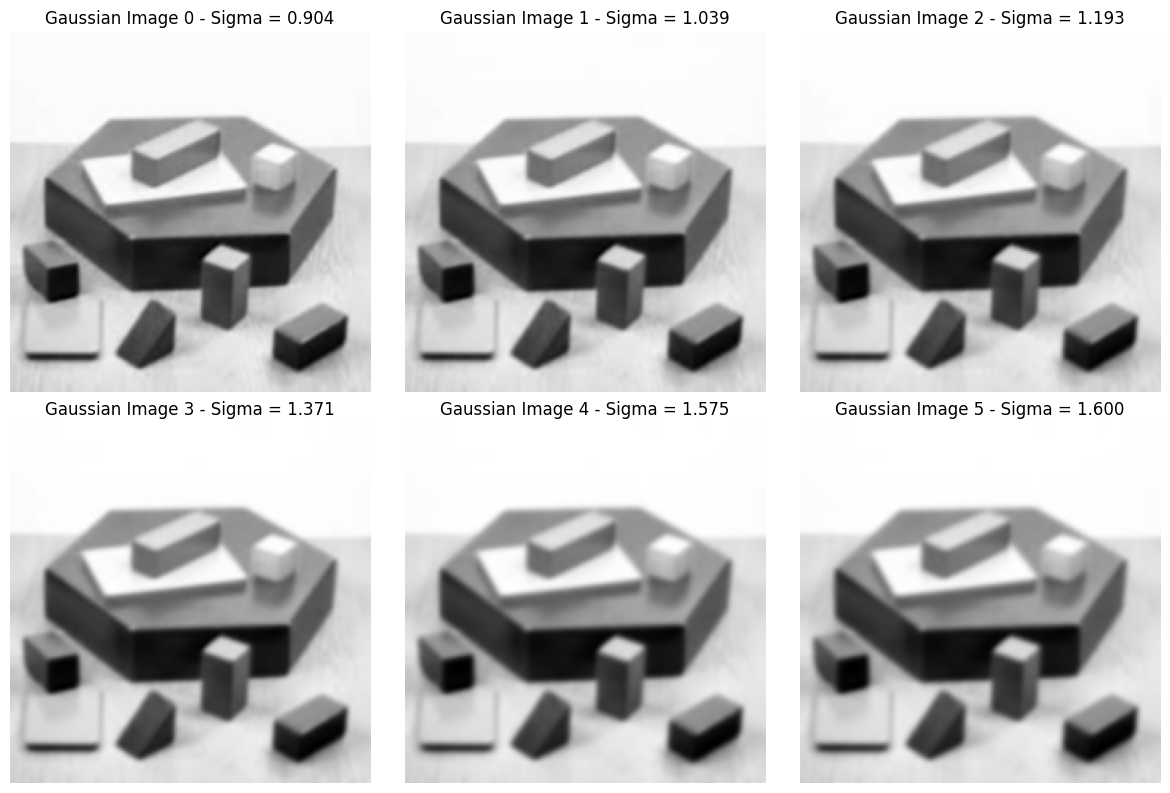

In [11]:
import matplotlib.pyplot as plt

def mostrar_6_imagenes(imgs, titles=None):
    """

    imgs: lista de 6 imágenes (BGR o RGB)
    titles: lista opcional de 6 títulos

    """

    plt.figure(figsize=(12, 8))
    
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        
        img = imgs[i]
        # Si la imagen está en BGR, convertir a RGB
        if len(img.shape) == 3:
            img_plot = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        else:
            img_plot = img
        
        plt.imshow(img_plot, cmap="gray")
        
        if titles is not None:
            plt.title(titles[i])
        
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

# Definimos los títulos que queremos mostrar en el plot
mis_titulos = [f"Gaussian Image {i} - Sigma = {sigmas[i]:.3f}" for i in range(len(gaussian_images))]

# Como teníamos 6 sigmnas, ahora tenemos 6 imágenes con distintos blurs aplicados
mostrar_6_imagenes(gaussian_images, mis_titulos)



### Adicionalmente, probamos a generar otras gaussianas partiendo de una sigma base distinta para interpretar los resultados y comprender el funcionamiento del hiperparámetro sigma en este proceso:

In [12]:
intervals_testing = 5

# Initial sigma
sigma_testing = 2.5  # Sigma inicial de las 6 que va a haber en total

# We get the necessary sigmas from the given method generateGaussianSigmas()

# Función perteneciente a utils.py que nos permite generar una lista de sigmas, kernels gaussianos para aplicar el blur a la imagen
sigmas_testing = sorted(generateGaussianSigmas(sigma_testing, intervals_testing))  #  recibe la sigma inicial y el número de diferencias de gaussianas que queremos generar

# Generate the gaussian images
gaussian_images_testing = generateGaussianImages(image, sigmas_testing)

In [13]:
print(len(gaussian_images_testing))
print(len(sigmas_testing))
print(sigmas_testing)

6
6
[1.4131257701742581, 1.6232552476030884, 1.8646306326619728, 2.141898140415889, 2.4603948704669416, 2.5]


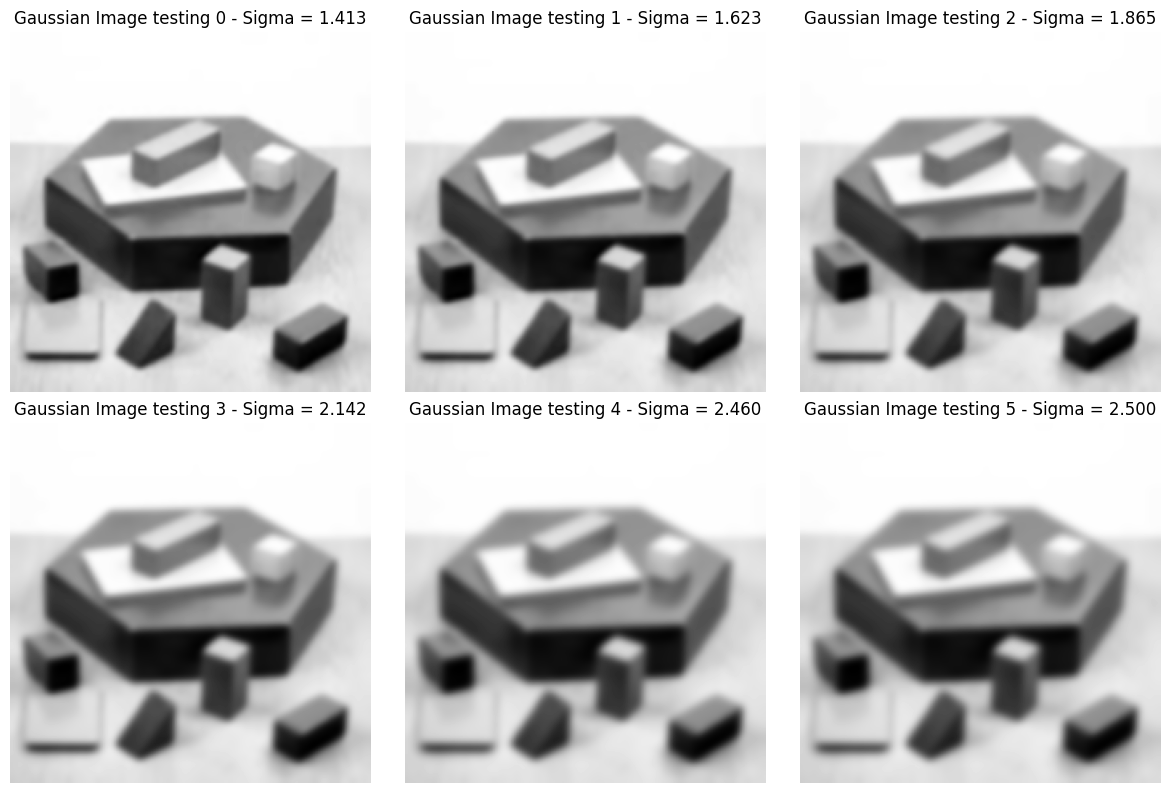

In [14]:
# Definimos los títulos que queremos mostrar en el plot
mis_titulos_testing = [f"Gaussian Image testing {i} - Sigma = {sigmas_testing[i]:.3f}" for i in range(len(gaussian_images_testing))]

# Como teníamos 6 sigmnas, ahora tenemos 6 imágenes con distintos blurs aplicados
mostrar_6_imagenes(gaussian_images_testing, mis_titulos_testing)

La generación de imágenes gaussianas constituye un paso fundamental en el algoritmo que estamos desarrollando en esta práctica, ya que nos permite analizar la información visual de nuestras imágenes a distintos niveles de suavizado. El parámetro sigma controla la desviación estándar del filtro gaussiano y, por tanto, determina la magnitud del desenfoque aplicado a la imagen original. Su valor define cuánta información de alta frecuencia (bordes finos, texturas y detalles) será eliminada en cada nivel de la pirámide que vamos construyendo.

Cuando se emplea un sigma inicial aceptable, como 1.6, el suavizado aplicado en las sucesivas gaussianas es relativamente moderado. Las imágenes mantienen buena parte de la estructura y los contornos principales permanecen definidos. Esto es coherente con lo que hemos obtenido en la parte previa a esta exploración adicional, donde las distintas escalas conservaban formas reconocibles y el borrado progresivo era lo suficientemente suave. Este rango de sigma favorece que los detectores identifiquen puntos de interés estables, ya que la imagen no pierde en exceso los detalles relevantes entre niveles consecutivos.

Por el contrario, cuando se parte de un sigma inicial mayor, como 2.5, que es el que hemos probado ahora adicionalmente, el efecto de difuminado se incrementa significativamente. Cada nivel de la pirámide atenúa de manera más agresiva las altas frecuencias, lo que produce imágenes mucho más borrosas y con bordes menos definidos. Este comportamiento se observa claramente en las gaussianas generadas con sigma de valores superiores a 2, donde las estructuras geométricas de la escena se vuelven rápidamente más planas y homogéneas. A partir de ciertos niveles, algunos bordes desaparecen casi por completo, lo que puede dificultar la correcta detección de características.

En resumen, un incremento del parámetro sigma implica una pérdida progresiva de detalle, mayor suavizado y, por tanto, una representación más pobre de las variaciones locales de intensidad. Reducir sigma genera imágenes más nítidas y cercanas a la original, mientras que aumentarlo produce gaussianas más distorsionadas y simplificadas. El valor óptimo depende del equilibrio entre eliminar ruido y preservar estructura: un sigma demasiado bajo puede mantener variaciones irrelevantes, mientras que uno demasiado alto puede eliminar información crucial para etapas posteriores del algoritmo. En nuestro caso, tras sucesivas pruebas, hemos tomado un sigma inicial de 1.6 que nos funciona adecuadamente.

### **Tarea B.3**: Generación de diferencias de gaussianas

Utilizando la lista de imágenes gaussianas se generará una lista con las diferencias entre pares consegutivos. Para ello se empleará la función `generateDoGImages()` que tiene que desarrollar empleando la función [`cv2.subtract()`](https://docs.opencv.org/4.x/d2/de8/group__core__array.html#gaa0f00d98b4b5edeaeb7b8333b2de353b)

In [15]:
def generateDoGImages(gaussian_images):
    """

    Generate Difference-of-Gaussians list

    Args:
        gaussian_images (List[np.array[np.float32]): List of blurred images

    Returns:
        List[np.array[np.float32]: List of difference of gaussian images

    """

    dog_images = []  # Inicializamos la lista vacía donde vamos a almacenar las imágenes resultado

    # TODO: Generate the list of difference of gaussians using cv2.subtract()
    for i in range(len(gaussian_images) - 1):  # Iteramos desde la primera foto hasta la penúltima, sin llegar a la última para no salirnos del rango al operar la resta
        dog_img = cv2.subtract(gaussian_images[i+1], gaussian_images[i]) # Aplicamos la operación: Imagen i+1 ésima - Imagen i ésima
        dog_images.append(dog_img.astype(np.float32))  # Guardamos el resultado en nuestra lista
    
    return dog_images

dog_images = generateDoGImages(gaussian_images)

In [16]:
# Debemos tener 5 resultados de las diferencias entre gaussianas ya que teníamos 6 gaussianas:
print(len(gaussian_images))
print(len(dog_images))

6
5


In [17]:
for i, img in enumerate(dog_images):
    show_image(img, img_name=f"DoG Image {i}")
    save_path = f"../output/partB/dog_image_{i}.jpg"
    write_image("../output/partB", f"dog_image_{i}.jpg", img.astype(np.uint8))

In [18]:
# Una representación conjunta para verlo mejor:

def mosaic_3_2(imgs):
    """
    Crea un mosaico 3+2 usando las imágenes tal cual están (BGR).
    imgs: lista de 5 imágenes
    return: mosaico como imagen BGR
    """
    if len(imgs) != 5:
        raise ValueError("Debes pasar exactamente 5 imágenes.")

    # Aseguramos que todas las imágenes tengan el mismo tamaño
    h, w = imgs[0].shape[:2]
    resized = [cv2.resize(img, (w, h)) for img in imgs]

    # Fila 1: 3 imágenes
    row1 = np.hstack((resized[0], resized[1], resized[2]))

    # Fila 2: 2 imágenes + un hueco negro para completar
    empty = np.zeros_like(resized[0])
    row2 = np.hstack((resized[3], resized[4], empty))

    # Juntar filas
    mosaic = np.vstack((row1, row2))

    return mosaic

mosaic = mosaic_3_2(dog_images)
show_image(mosaic, "DoG Images")


### **Tarea B.4**: Evaluación de extremos

La función `isPixelAnExtremum()` debe evaluar si el pixel central del bloque compuesto por las regiones de las 3 imágenes es un máximo o mínimo entre ellos. Como prevención, tenga en cuenta que puede tomar valores positivos y negativos

In [19]:
def isPixelAnExtremum(first_subimage, second_subimage, third_subimage, threshold):
    """Return True if the center element of the 3x3x3 array composed of subimages is strictly greater than or less than all its neighbors, False otherwise

    Args:
        first_subimage (np.array): Patch from first gaussian
        second_subimage (np.array): Patch from second gaussian
        third_subimage (np.array): Patch from third gaussian
        threshold (float): Value threshold for the pixel

    Returns:
        Bool: True if maximum or minimum, False otherwise
    """

    # TODO: Check if the center pixel value is a maximum or a minimum and if its absolute value is higher than the threshold
    center_value = float(second_subimage[1, 1])

    if abs(center_value) < float(threshold):  # Si el valor es inferior en valor absoluto al threshold, directamente devolvemos False
        return False
    
    # La segunda comprobación es la de que sea el máximo entre sus vecinos 
    neighbor_values = []
    for plane in (first_subimage, second_subimage, third_subimage):
        for i in range(3):  # Porque usamos estructura de 3x3
            for j in range(3):  # Porque usamos estructura de 3x3
                if i == 1 and j == 1 and plane is second_subimage: # no añadimos el propio pixel central como vecino
                    continue  # Skip the center pixel itself 
                neighbor_values.append(float(plane[i, j]))  # añadimos los vecinos a nuestro pixel, de cada una de las capas (primera, segunda y tercera)
                    
    # Comprobamos si el valor de nuestro pixel, o es mayor que todos, o es menor que todos los vecinos. En caso de ser así: True, sino: False
    extremum = (center_value > max(neighbor_values)) or (center_value < min(neighbor_values))

    return extremum  # Devolvemos el booleano como resultado

In [20]:
# Hacemos una prueba para comprobar que la función de isPixelAnExtremum está bien implementada

# Creamos 3 capas enteras de ceros, pero poniendo el elemento central (de la segunda capa) como un 1
first_subimage = np.zeros((3,3),np.float32)
third_subimage = np.zeros((3,3),np.float32)
second_subimage = np.zeros((3,3),np.float32)
second_subimage[1,1] = 1
threshold = 0.03

isPixelAnExtremum(first_subimage,second_subimage, third_subimage, threshold)  # Debe dar True

True

In [21]:
# Hacemos una prueba para comprobar que la función de isPixelAnExtremum está bien implementada

# Creamos 3 capas enteras de ceros, pero poniendo el elemento central (de la segunda capa) como un -0.02
first_subimage = np.zeros((3,3),np.float32)
third_subimage = np.zeros((3,3),np.float32)
second_subimage = np.zeros((3,3),np.float32)
second_subimage[1,1] = -0.02
threshold = 0.03

isPixelAnExtremum(first_subimage,second_subimage, third_subimage, threshold)  # Debe dar False

False

### **Tarea B.5**: Localización de puntos clave y orientación de los mismos

La función `findScaleSpaceExtrema()` obtendrá los puntos clave y su orientación a partir de las gaussianas y sus diferencias empleando, entre otras, la función `isPixelAnExtremum()`. Deberá completar las partes indicadas para recorrer todos los trios de imágenes consecutivos y evaluar los píxeles necesarios de estos.

Keypoints - Threshold = 0.1


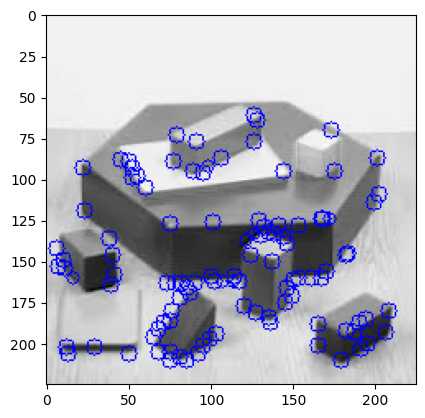

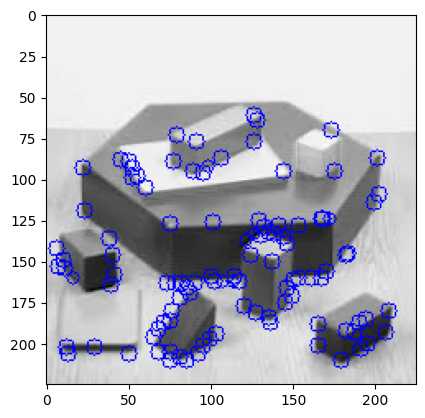

In [22]:
def findScaleSpaceExtrema(gaussian_images, dog_images, num_intervals, sigma, threshold=0.03):
    """Find pixel positions of all scale-space extrema in the image pyramid """
    keypoints = []  # Inicializamos una lista de puntos clave que vamos a ir rellenando

    # TODO: Fill the loop source data
    for image_index in range(len(dog_images) - 2):  # Cogemos trios desde las imágenes (0,1,2) hasta las (n-2, n-1, n)
        first_image = dog_images[image_index]  # Primera capa (primer índice)
        second_image = dog_images[image_index + 1]  # Segunda capa (segundo índice)
        third_image = dog_images[image_index + 2]  # Tercera capa (tercer índice)

        # (i, j) is the center of the 3x3 array

        # TODO: Fill the 2 range limits knowing you have to move the 3x3 window across the whole image
        for i in range(1,second_image.shape[0]-1):  # Nos tenemos que saltar el índice 0 porque al usar path de 3x3 nos saldríamos del rango
            for j in range(1,second_image.shape[1]-1):  # Nos tenemos que saltar el índice 0 porque al usar path de 3x3 nos saldríamos del rango
                # TODO: Fill the method with the required arguments
                if isPixelAnExtremum(first_image[i-1:i+2, j-1:j+2], # Cogemos desde la fila anterior hasta la fila siguiente y lo mismo con columnas (path 3x3)
                                    second_image[i-1:i+2, j-1:j+2], 
                                    third_image[i-1:i+2, j-1:j+2],
                                    threshold):  # Usamos el threshold que nos hayan pasado como argumento
                    
                    # Refine the keypoint localization
                    localization_result = localizeExtremumViaQuadraticFit(i, j, image_index + 1, num_intervals, dog_images, sigma)

                    """
                    localizeExtremumViaQuadraticFit toma la posición inicial (i,j)
                    y la refina buscando el verdadero máximo/minimo de la función DoG
                    mediante una aproximación en Taylor de segundo orden en 3D.

                    """

                    if localization_result is not None:
                        keypoint, localized_image_index = localization_result  # solo si el refinamiento ha sido satisfactorio
                        # Get the keypoint orientation
                        keypoints_with_orientations = computeKeypointsWithOrientations(keypoint, gaussian_images[localized_image_index])

                        """
                        computeKeypointsWithOrientations calcula el gradiente
                        alrededor del punto clave en la imagen gaussiana y asigna
                        la orientación principal y secundarias detectadas

                        """
                        for keypoint_with_orientation in keypoints_with_orientations:
                            # Finalmente añadimos todos los keypoints generados (puede haber más de uno)
                            keypoints.append(keypoint_with_orientation)
    return keypoints

# Keypoint Detection with Taylor Expansion and Contrast Thresholding
# Tras múltiples pruebas hemos optado por usar este valor de threshold. Más adelante aportamos un análisis más detallado del significado de este hiperparámetro
threshold = 0.1 
keypoints = findScaleSpaceExtrema(gaussian_images, dog_images, intervals, sigma, threshold)
print(f"Keypoints - Threshold = {threshold}")
visualizeKp(image.copy(), keypoints)  # Llamamos a la función usando una copia de la imagen original, por si acaso, no queremos sobreescribirla
keypoints = removeDuplicateKeypoints(keypoints)
visualizeKp(image.copy(), keypoints)  # Llamamos a la función usando una copia de la imagen original, por si acaso, no queremos sobreescribirla

### Exploración adicional con distintos valores de thresholds para interpretar los resultados y comprender el funcionamiento del hiperparámetro threshold en este proceso:

Keypoints - Threshold = 0.1


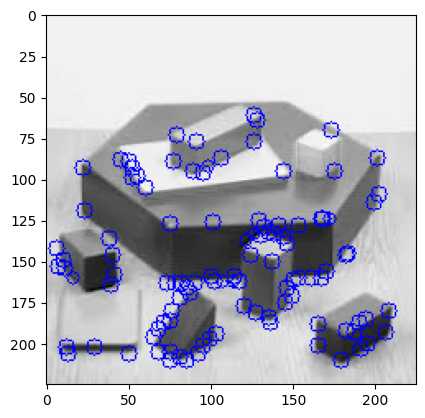

Keypoints - Threshold = 4


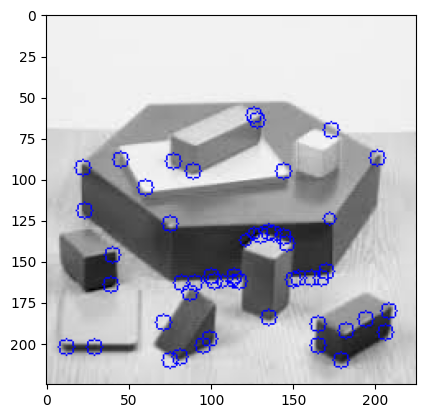

Keypoints - Threshold = 6


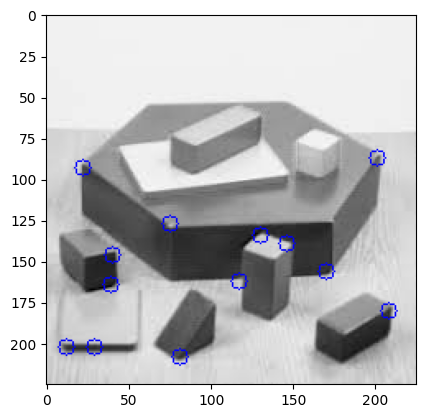

Keypoints - Threshold = 10


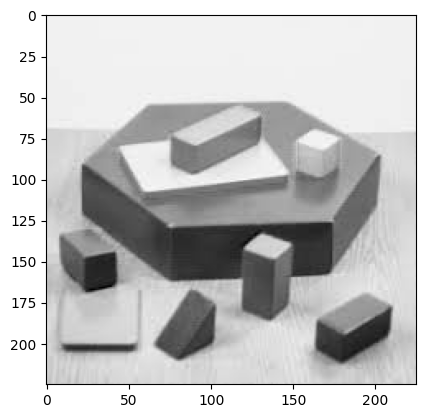

In [23]:
# Mostramos los resultados obtenidos usando distintos valores de threshold, para ver cuáles son los puntos clave más y menos importantes que se detectan:
thresholds = [0.1, 4, 6, 10]

for th in thresholds:
    # Keypoint Detection with Taylor Expansion and Contrast Thresholding
    keypoints_th = findScaleSpaceExtrema(gaussian_images, dog_images, intervals, sigma, th)
    print(f"Keypoints - Threshold = {th}")
    keypoints_th = removeDuplicateKeypoints(keypoints_th)
    visualizeKp(image.copy(), keypoints_th)

En los resultados obtenidos podemos observar claramente cómo el parámetro threshold influye en la detección de puntos clave, lo cual es muy importante dentro del proceso que estamos realizando, basado en Difference of Gaussians. Este umbral actúa como filtro de contraste: determina qué nivel mínimo debe presentar la respuesta DoG para que un píxel sea considerado candidato a extremum. Al modificarlo se altera directamente la sensibilidad del detector y, por tanto, la densidad y relevancia de los keypoints extraídos.

Cuando se utiliza un threshold bajo, como por ejemplo 0.1, el detector se vuelve más sensible a cualquier variación presente en la imagen. Esto provoca que se identifiquen multitud de puntos clave distribuidos por toda la escena, incluso que haya alguno en zonas planas o en regiones donde el cambio de intensidad es muy pequeño. La consecuencia es que se detectan muchos puntos clave, algunos claramente útiles y otros, aunque sean pocos puede que hayan sido generados por ruido o microvariaciones que no representan estructuras tan relevantes. Sin embargo, este comportamiento también garantiza que ningún detalle potencialmente significativo se pierda, ya que el sistema capta incluso las irregularidades más sutiles.

Al aumentar el valor del threshold hacia niveles medios, como 4 o 6, el detector comienza a filtrar gran parte de estas respuestas débiles. Solo permanecen puntos asociados a cambios más pronunciados en el DoG, como esquinas bien definidas, intersecciones de aristas o zonas donde existe un contraste notable entre intensidades. El resultado muestra un conjunto de keypoints más limpio, compuesto principalmente por estructuras visualmente prominentes y, por tanto, más estables. Este comportamiento representa un equilibrio entre exceso y defecto: se descarta ruido pero se conservan puntos significativos.

Si el threshold se incrementa hasta valores altos, como 10, la detección se vuelve extremadamente restrictiva. En este caso aparecen muy pocos puntos clave, y en algunas zonas del objeto directamente no se detecta ninguno. En estos casos, la información obtenida es insuficiente para tareas posteriores como correspondencia entre imágenes, extracción de descriptores robustos o clasificación basada en características locales.

Teniendo en cuenta el propósito general de este tipo de detectores, especialmente en el contexto de nuestra práctica, donde posteriormente se usarán estos keypoints para alimentar un sistema de descripción y clasificación, resulta preferible optar por configuraciones que proporcionen un número amplio de detecciones. Es cierto que los valores bajos de threshold generan una gran cantidad de puntos, algunos de los cuales pueden ser ruidosos o excesivos, pero esto también garantiza que se capturen todos los detalles importantes de la escena. En cambio, un threshold demasiado elevado compromete la capacidad del algoritmo para caracterizar adecuadamente la imagen, ya que elimina excesivamente la riqueza estructural necesaria para el análisis posterior.

Por todo ello, aunque un threshold intermedio (4) podría ofrecer un equilibrio razonable, desde una perspectiva práctica hemos optado por elegir un threshold más bajo que asegure una detección abundante de keypoints. Creemos que es preferible gestionar posteriormente la posible redundancia de keypoints, antes que correr el riesgo de quedarse con un conjunto demasiado escaso que no represente adecuadamente la complejidad de la imagen.


---

Con los puntos clave totalmente definidos y las imágenes gaussianas ya podemos obtener los descriptores con la función proporcionada de `generateDescriptors()`

In [24]:
# Utilizamos la función que se nos proporciona en el fichero utils.py
descriptors = generateDescriptors(keypoints, gaussian_images)

La función generateDescriptors toma los keypoints detectados (con posición, orientación y escala refinadas), las imágenes gaussianas (pirámide), y devuelve un descriptor de 128 dimensiones por cada keypoint. Este es el descriptor de SIFT

In [ ]:
# Exploramos un poco el aspecto de los descriptores para entender mejor con qué estamos trabajando
print(descriptors, "\n")
print("Hay " , len(descriptors)," descriptores \n")
print("La shape de los descriptores es :", descriptors[0].shape,"\n")


[[ 77.  16.   0. ...   0.   0.   1.]
 [ 83. 148.   2. ...   4.  13.   0.]
 [  6.   7.   0. ...   6.  21.   9.]
 ...
 [ 50.  15.   2. ...   1.   0.   2.]
 [  0.   0.   6. ...   1.   1.   5.]
 [  0.  75.  50. ...   0.   0.   0.]] 

Hay  119  descriptores 

La shape de los descriptores es : (128,) 



### ¿Qué son los descriptores en este contexto?

En el proceso SIFT, los keypoints son puntos de interés: lugares de la imagen que han sido seleccionados porque presentan un máximo o mínimo claro en el espacio de escala (estructuras estables, esquinas, puntos con identidad propia). Pero un keypoint por sí solo no es suficiente para comparar imágenes. Lo que necesitamos es una descripción numérica de cómo es la vecindad alrededor de ese keypoint: cómo cambian los gradientes, en qué orientación, con qué magnitud…

Eso es precisamente un descriptor:

Un descriptor es un vector numérico que resume el patrón local de intensidades alrededor de un keypoint, de forma que:

- Es robusto a cambios de iluminación

- Robusto a rotaciones, más o menos robusto a cambios de escala

- Permite comparar puntos entre imágenes distintas.

En SIFT, el descriptor clásico es un vector de 128 elementos, que es justo lo que hemos visto que tiene almacenado cada uno de los descriptores que hemos obtenido en las celdas de arriba.

En definitiva, los keypoints representan puntos importantes de la imagen, que nos indican algo así como dónde hay que mirar para identificar las características más importantes de la imagen. Por otro lado, los descriptores representan qué es eso importante que hay en el punto de interés, de alguna forma lo describen.


### **Tarea B.6**: Pipeline de generación de puntos clave y descriptores

Complete la función con los métodos desarrollados en tareas previas para generar los puntos clave y descriptores necesarios dada una imagen, un valor de sigma y un número de diferencias de gaussianas

In [39]:
def computeKeypointsAndDescriptors(image, sigma=1.6, num_intervals=5, th=0.8):
    """Compute SIFT keypoints and descriptors for an input image """
    # TODO: Fill the pipeline to get the keypoint and descriptors as before
    
    # Asegurarnos de que trabajamos con float32, como en SIFT original
    image = image.astype(np.float32)

    # Generamos los kernels gaussianos (las sigmas correspondientes)
    gaussian_kernels = sorted(generateGaussianSigmas(sigma, num_intervals))

    # Generamos la pirámide de imágenes gaussianas
    gaussian_images = generateGaussianImages(image, gaussian_kernels)

    # Generamos las diferencias de gaussianas (DoG)
    dog_images = generateDoGImages(gaussian_images)

    # Detectamos los keypoints en el espacio de escalas
    keypoints = findScaleSpaceExtrema(gaussian_images, dog_images, num_intervals, sigma, threshold=th)
    keypoints = removeDuplicateKeypoints(keypoints)

    # Generamos los descriptores para los keypoints
    descriptors = generateDescriptors(keypoints, gaussian_images)

    return keypoints, descriptors

### **Tarea B.7**: Correspondencia de características entre imágenes

Cargue las imágenes con `cv2` y complete la llamada a la función previa

Shape de las imágenes: 
(225, 225)
(225, 225)

Resultados de la extracción de keypoints y descriptores:
KP1 = 119 - DES1 = (119, 128)
KP2 = 120 - DES2 = (120, 128)


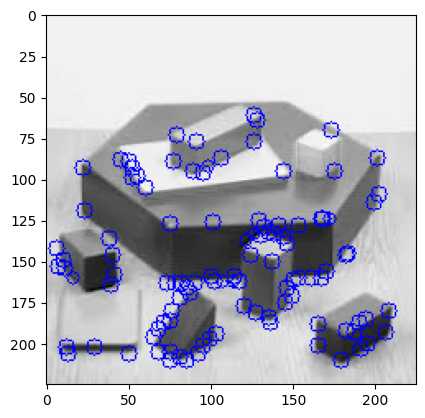

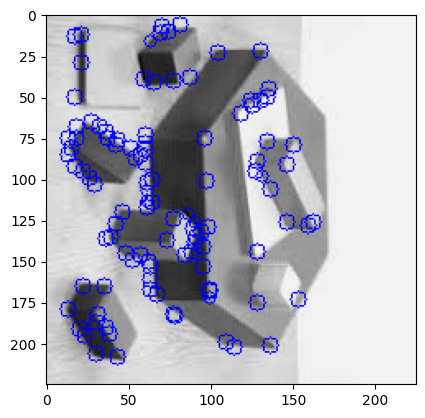

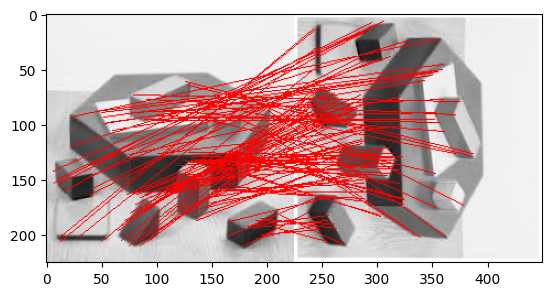

In [ ]:
# TODO: Load the images with cv2 in grayscale

img1 = cv2.imread(imgs_path[0], cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(imgs_path[1], cv2.IMREAD_GRAYSCALE)

# Ponemos algunos datos antes de realizar el proceso de detección de keypoints y extracción de los descriptores
print("Shape de las imágenes: ")
print(img1.shape)
print(img2.shape)
# show_image(img1, "Imagen 1")
# show_image(img2, "Imagen 2")
print()
 
# TODO: Fill the function calls
# Obtenemos tanto los keypoints como los descriptores de ambas imágenes (la original y la rotada)
kp1, des1 = computeKeypointsAndDescriptors(img1)
kp2, des2 = computeKeypointsAndDescriptors(img2)
# No especificamos parámetros en la función ya que queremos usar los valores por defecto de sigma (1.6), número de intervalos (5) y threshold (0.8)

print("Resultados de la extracción de keypoints y descriptores:")
print("KP1 =", len(kp1), "- DES1 =", None if des1 is None else des1.shape)
print("KP2 =", len(kp2), "- DES2 =", None if des2 is None else des2.shape)

# Llamamos a la función de visualizar con copias de las imágenes originales ya que no queremos sobreescribirlas al pintar los keypoints
visualizeKp(img1.copy(), kp1)
visualizeKp(img2.copy(), kp2)

# Establecemos la correspondencia entre los puntos de interés de ambas imágenes
matchFeatures(img1, kp1, des1, img2, kp2, des2) 


### Exploramos cómo quedan las correspondencias entre imágenes usando distintos valores del hiperparámetro threshold: 

Shape de las imágenes: 
(225, 225)
(225, 225)

Resultados de la extracción de keypoints y descriptores para th = 1:
KP1 = 119 - DES1 = (119, 128)
KP2 = 119 - DES2 = (119, 128)


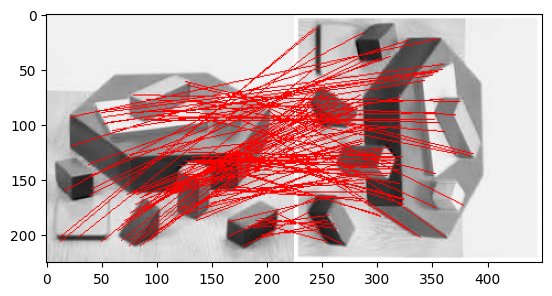

Resultados de la extracción de keypoints y descriptores para th = 4:
KP1 = 59 - DES1 = (59, 128)
KP2 = 59 - DES2 = (59, 128)


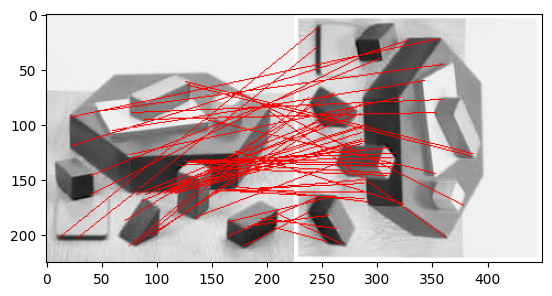

Resultados de la extracción de keypoints y descriptores para th = 6:
KP1 = 17 - DES1 = (17, 128)
KP2 = 17 - DES2 = (17, 128)


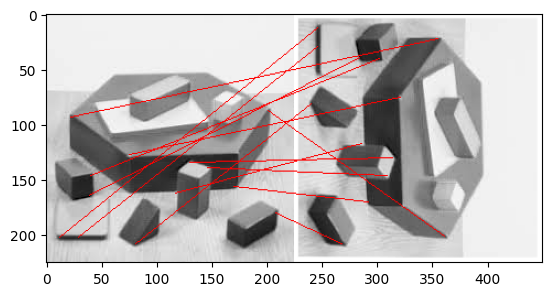

In [44]:
# Ponemos algunos datos antes de realizar el proceso de detección de keypoints y extracción de los descriptores
print("Shape de las imágenes: ")
print(img1.shape)
print(img2.shape)
print()

# Distintos valores de thresholds que vamos a probar
thresholds = [1, 4, 6]

for th in thresholds:
    
    # Obtenemos tanto los keypoints como los descriptores de ambas imágenes (la original y la rotada)
    kp1_, des1_ = computeKeypointsAndDescriptors(img1, th=th)
    kp2_, des2_ = computeKeypointsAndDescriptors(img2, th=th)
    # Especificamos el th concreto que usamos para esta iteración 

    print(f"Resultados de la extracción de keypoints y descriptores para th = {th}:")
    print("KP1 =", len(kp1_), "- DES1 =", None if des1_ is None else des1_.shape)
    print("KP2 =", len(kp2_), "- DES2 =", None if des2 is None else des2_.shape)

    # Establecemos la correspondencia entre los puntos de interés de ambas imágenes
    matchFeatures(img1, kp1_, des1_, img2, kp2_, des2_) 

#### **Ampliación**: SIFT con OpenCV

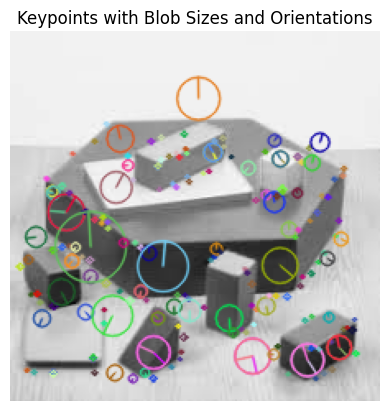

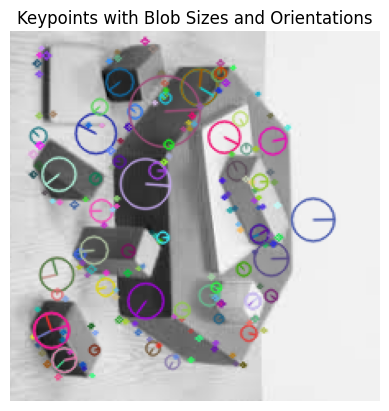

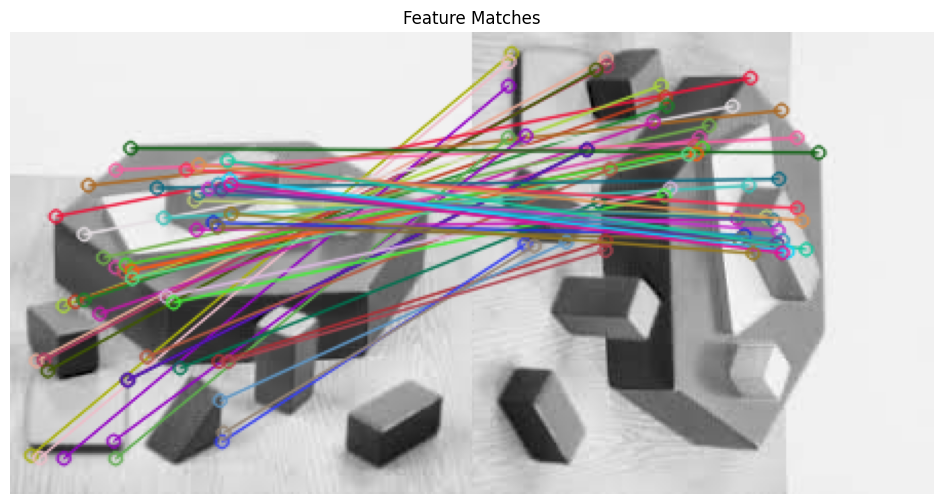

In [74]:
# Load the image
image_0 = cv2.imread('../data/PartB/0.jpg', cv2.IMREAD_GRAYSCALE)
image_1 = cv2.imread('../data/PartB/0_rot.jpg', cv2.IMREAD_GRAYSCALE)

# Create a SIFT detector object
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints_0, descriptors_0 = sift.detectAndCompute(image_0, None)
keypoints_1, descriptors_1 = sift.detectAndCompute(image_1, None)

# Draw keypoints on the image
image_with_keypoints_0 = cv2.drawKeypoints(image_0, keypoints_0, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints_1 = cv2.drawKeypoints(image_1, keypoints_1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.imshow(image_with_keypoints_0)
plt.title('Keypoints with Blob Sizes and Orientations')
plt.axis('off')
plt.show()
plt.imshow(image_with_keypoints_1)
plt.title('Keypoints with Blob Sizes and Orientations')
plt.axis('off')
plt.show()

# Initialize BFMatcher
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Perform KNN matching with k=2 for ratio test
matches = bf.match(descriptors_0, descriptors_1)

# sort matches by distance
matches = sorted(matches, key = lambda x:x.distance)


# Draw the good matches
matched_image = cv2.drawMatches(image_0, keypoints_0, image_1, keypoints_1, matches[:50], None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# Display the matched features
plt.figure(figsize=(12, 6))
plt.imshow(matched_image)
plt.title("Feature Matches")
plt.axis('off')
plt.show()

### **Pregunta B1**: Correspodencia de imágenes propias y evaluación

### Nuestro pipeline propio:

In [75]:
# Cargamos nuestra propia imagen y la rotamos para así tener las 2 imágenes de trabajo. También la recortamos para que sea de 255x255
image_0 = cv2.imread('../data/PartB/estudio.jpg', cv2.IMREAD_GRAYSCALE)

h, w = image_0.shape

# Tamaño deseado
new_size = 300

# Coordenadas del recorte centrado
start_row = (h - new_size) // 2
start_col = (w - new_size) // 2

image_0 = image_0[start_row:start_row + new_size,
              start_col:start_col + new_size]

cv2.imshow("Recorte centrado 255x255", image_0)
cv2.waitKey(0)
cv2.destroyAllWindows()

image_1 = cv2.rotate(image_0, cv2.ROTATE_90_CLOCKWISE)

KP1 = 261 DES1 = (261, 128)
KP2 = 261 DES2 = (261, 128)


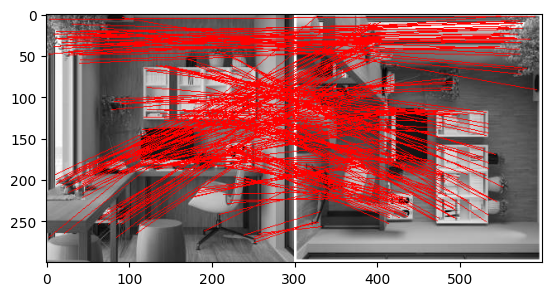

In [76]:
# TODO: Homework

kp1, des1 = computeKeypointsAndDescriptors(image_0)
kp2, des2 = computeKeypointsAndDescriptors(image_1)

print("KP1 =", len(kp1), "DES1 =", None if des1 is None else des1.shape)
print("KP2 =", len(kp2), "DES2 =", None if des2 is None else des2.shape)

matchFeatures(image_0, kp1, des1, image_1, kp2, des2) # Establecemos la correspondencia entre los puntos de interés de ambas imágenes

# Esta parte no nos funciona, no sé por qué TODO 

### Método propio de OpenCV:

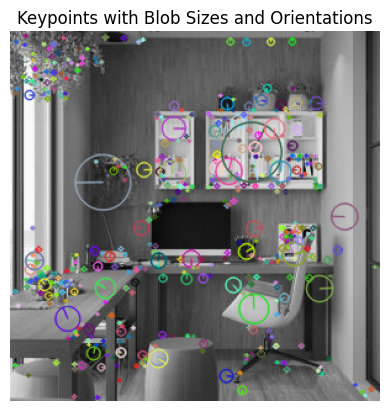

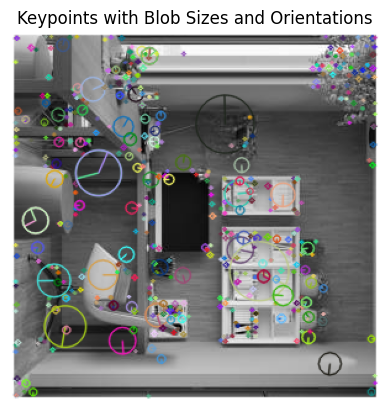

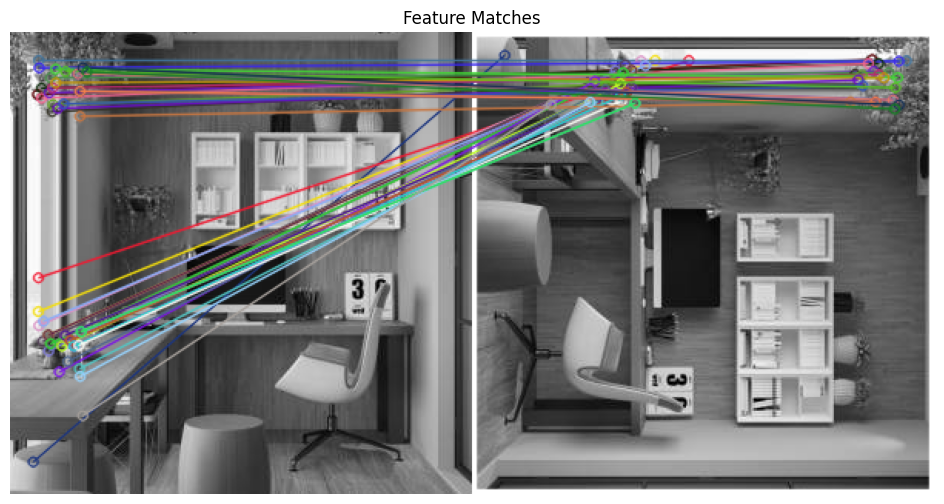

In [77]:
# Create a SIFT detector object
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints_0, descriptors_0 = sift.detectAndCompute(image_0, None)
keypoints_1, descriptors_1 = sift.detectAndCompute(image_1, None)

# Draw keypoints on the image
image_with_keypoints_0 = cv2.drawKeypoints(image_0, keypoints_0, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints_1 = cv2.drawKeypoints(image_1, keypoints_1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.imshow(image_with_keypoints_0)
plt.title('Keypoints with Blob Sizes and Orientations')
plt.axis('off')
plt.show()
plt.imshow(image_with_keypoints_1)
plt.title('Keypoints with Blob Sizes and Orientations')
plt.axis('off')
plt.show()

# Initialize BFMatcher
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Perform KNN matching with k=2 for ratio test
matches = bf.match(descriptors_0, descriptors_1)

# sort matches by distance
matches = sorted(matches, key = lambda x:x.distance)


# Draw the good matches
matched_image = cv2.drawMatches(image_0, keypoints_0, image_1, keypoints_1, matches[:50], None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# Display the matched features
plt.figure(figsize=(12, 6))
plt.imshow(matched_image)
plt.title("Feature Matches")
plt.axis('off')
plt.show()

## **B2: Bolsa de palabras**

### **Tarea B.2.1**: Carga de los datasets de entrenamiento y validación para la bolsa de palabras

Descargue el dataset desde el [`enlace en Mooodle`](https://sifo.comillas.edu/pluginfile.php/5039369/mod_page/content/8/dataset.zip), descomprimalo en \data\partB. 

Empleando el método `load()` de la clase [`Dataset`](.\dataset.py) que se le proporciona, cargue los datasets de entrenamiento y validación.

In [78]:
# Cargamos los datasets usando la extensión de jpg que tienen todas las imágenes que están en dicho dataset
training_set = Dataset.load("../data/partB/dataset/training", file_extension="jpg")
validation_set = Dataset.load("../data/partB/dataset/validation", file_extension="jpg")

### **Tarea B.2.2**: Extracción de los descriptores

Para poder crear la bolsa de palabras se va a comenzar obteniendo los descriptores que serán agrupados en las distintas palabras de nuestra bolsa. Para ello complete la carga de la imagen en la ruta `path` en escala de grises y obtenga sus descriptores con los métodos apropiados de cv2. Los descriptores obtenidos se añadirán a nuestra bolsa de palabras (`words`) para después ser agrupados por palabras que representen

In [79]:
feature_extractor = cv2.SIFT_create()

"""
crea un objeto SIFT oficial de OpenCV, que tiene dos funciones clave:

detect() detecta keypoints

compute() calcula descriptores SIFT

detectAndCompute() hace ambos a la vez

"""

# Extract features
print("\nComputing SIFT descriptors...")
time.sleep(0.1)  # Prevents a race condition between tqdm and print statements.
descriptors = []

for path in tqdm(training_set, unit="image", file=sys.stdout):
    # TODO: Load the image from the path in grayscale
    image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)  # importante añadir la flag para que se cargue la imagen en escala de grises
    try:
        # TODO: Using the cv2 methods get the descriptors for the image
        _, descriptor = feature_extractor.detectAndCompute(image, None)  # Usamos el método del feature_extractor que habíamos creado
        # Aquí podríamos llamar también a nuestra función de computeKeypointsAndDescriptors, pero se nos pide usar métodos de cv2
    except:
        print(f"WARN: Issue generating descriptor for image {path}")

    if descriptor is not None:
        descriptors.append(descriptor)


Computing SIFT descriptors...
100%|██████████| 2981/2981 [01:26<00:00, 34.40image/s]


In [80]:
print(len(descriptors))
print(descriptors[11].shape)
print(descriptors[20].shape)

2981
(405, 128)
(386, 128)


### **Tarea B.2.3**: Creación del vocabulario

Añada los descriptores a la bolsa (`words`) con el método add de la misma. Con los descriptores en la bolsa, se va a realizar el agrupamiento de los mismos por palabras para obtener un vocabulario de palabras visuales. Complete la ruta de apertura del archivo y establezca el modo de apertura en escrituria y bineario para poder guardar el vocabulario generado.

In [ ]:
"""
Explicación para nosostros mismos entender mejor el proceso que estamos realizando:

Si el tamaño del vocabulario es vocabulary_size = 100, entonces la variable vocabulary = words.cluster() contiene:

Una matriz de tamaño 100 x 128  (128 porque los descriptores SIFT tienen 128 dimensiones)

Cada fila es un centroide, es decir:

    un "tipo de parche" visual típico

    una palabra visual

    un cluster del espacio descriptor

Entonces por ejemplo en la fila 0, tendremos la "palabra visual 0" que será  el promedio de todos los descriptores SIFT que cayeron en el cluster 0.

Representa, por ejemplo:

    un borde vertical fuerte

    o una esquina derecha

    o un patrón repetitivo

Cuando llega una imagen nueva:

    obtenemos sus descriptores SIFT

    para cada descriptor buscamos la palabra visual más cercana

    
"""


# Build vocabulary
vocabulary_size = 100  # Parámetro que determina el número de palabras deseadas en el vocabulario final (afecta sobre cómo de bien/mal funciona el clasificador)
iterations = 20
termination_criteria = (cv2.TERM_CRITERIA_MAX_ITER | cv2.TERM_CRITERIA_EPS, iterations, 1e-6)
words = cv2.BOWKMeansTrainer(vocabulary_size, termination_criteria)

# TODO: Add all descriptors
all_descriptors = np.vstack(descriptors)  # Concatenamos los descriptores para que se puedan meter a "words" con la estructura correcta
words.add(all_descriptors)  # Añadimos los descriptores al entrenador de KMeans

time.sleep(0.1)  # Prevents a race condition between tqdm and print statements.
print("\nClustering descriptors into", vocabulary_size, "words using K-means...")
vocabulary = words.cluster()
filename=  "vocabulary.pickle"
# TODO: Open the file from above in the write and binay mode
with open(filename, "wb") as f:  # la "b" es de binary
    pickle.dump(["SIFT", vocabulary], f, pickle.HIGHEST_PROTOCOL)


Clustering descriptors into 100 words using K-means...


: 

: 

: 

### **Tarea B.2.4**: Entrenamiento del clasificador

Una vez se tiene el vocabulario de palabras visuales, se va a entrenar al classificador. Para ello haga uso de la clase [BoW](./bow.py) y complete los métodos que se le indican

In [ ]:
"""

Se va a entrenar un clasificador que sea capaz de diferenciar entre todos estos grupos de palabras visuales. 

Este será un modelo basado en una Support Vector Machine(SVM). 

Con este clasificador podremos recibir imágenes externas al dataset de entrenamiento y clasificarlas en nuestro grupo de palabras.

"""

bow = BoW()
# TODO: Especify the args for the loading method
bow.load_vocabulary(filename="vocabulary")  
# le pasamos el nombre del fichero .pickle (sin la extensión que si no da error) donde habíamos guardado nuestro vocabulario de palabras visuales

image_classifier = ImageClassifier(bow)
# TODO: Especify the args for the training method
image_classifier.train(training_set=training_set)  # indicamos cuál tiene que ser el dataset de entrenamiento para el modelo
classifier = "classifier"  
image_classifier.save(classifier)  # guardamos el modelo ya entrenado en un fichero .xml y con las etiquetas de categoría en un .json 



TRAINING CLASSIFIER

Extracting features...
100%|██████████| 2981/2981 [01:51<00:00, 26.72image/s]

Training SVM...


### **Tarea B.2.5**: Inferencia en dataset de entrenamiento
Con el modelo entrenado se procede a comprobar su desempeño con el dataset de entrenamiento. Complete los métodos indicados

In [ ]:
bow = BoW()

# TODO: Especify the args for the loading method
bow.load_vocabulary(filename="vocabulary")

image_classifier = ImageClassifier(bow)
# TODO: Especify the args for the loading method
image_classifier.load(filename=classifier)

# TODO: Especify the args for the loading method
image_classifier.predict(dataset=training_set, dataset_name="training_set")  # Este método automáticamente genera la matriz de confusión y nos proporciona el accuracy (0.58 en este caso)
# También nos genera un excel de resultados (training_set_results.xlsx) donde podemos analizar los resultados mejor



CLASSIFICATION RESULTS (TRAINING_SET)

Confusion matrix

KNOWN/PREDICTED  Bedroom  Coast  Forest  Highway  Industrial  Inside city  Kitchen  Living room  Mountain  Office  Open country  Store  Street  Suburb  Tall building
Bedroom             27.0    1.0     2.0      0.0        14.0          7.0      0.0         25.0       3.0     3.0           6.0   13.0     7.0     2.0            6.0
Coast                1.0  174.0     8.0     12.0         0.0          2.0      0.0          0.0      22.0     1.0          26.0    0.0     3.0     5.0            6.0
Forest               0.0    0.0   211.0      0.0         1.0          0.0      0.0          0.0       5.0     0.0          10.0    1.0     0.0     0.0            0.0
Highway              1.0   26.0     0.0     71.0        10.0          4.0      0.0          0.0       9.0     0.0           6.0    3.0     9.0     6.0           15.0
Industrial           5.0    6.0     2.0      2.0        83.0         24.0      0.0         14.0       9.0     4

(0.582690372358269,
 array([[ 27.,   1.,   2.,   0.,  14.,   7.,   0.,  25.,   3.,   3.,   6.,  13.,   7.,   2.,   6.],
        [  1., 174.,   8.,  12.,   0.,   2.,   0.,   0.,  22.,   1.,  26.,   0.,   3.,   5.,   6.],
        [  0.,   0., 211.,   0.,   1.,   0.,   0.,   0.,   5.,   0.,  10.,   1.,   0.,   0.,   0.],
        [  1.,  26.,   0.,  71.,  10.,   4.,   0.,   0.,   9.,   0.,   6.,   3.,   9.,   6.,  15.],
        [  5.,   6.,   2.,   2.,  83.,  24.,   0.,  14.,   9.,   4.,   3.,  24.,  16.,   7.,  12.],
        [  3.,   1.,   0.,   4.,  12., 135.,   0.,   7.,   0.,   2.,   2.,  15.,   9.,   2.,  16.],
        [  5.,   1.,   0.,   1.,  20.,  22.,  11.,  26.,   0.,  10.,   0.,   5.,   3.,   2.,   3.],
        [  7.,   1.,   0.,   0.,  13.,  11.,   2., 107.,   1.,  11.,   3.,  13.,   7.,   8.,   5.],
        [  0.,  28.,  19.,   2.,   0.,   0.,   0.,   1., 175.,   0.,  43.,   0.,   3.,   0.,   2.],
        [  8.,   0.,   0.,   0.,  10.,  14.,   3.,  23.,   0.,  43.,   0.,   5.,

### **Tarea B.2.6**: Inferencia en dataset de evaluación

A continuación se evalua el desempeño del modelo con el dataset de validación. Complete los métodos indicados

In [ ]:
bow = BoW()
# TODO: Especify the args for the loading method
bow.load_vocabulary(filename="vocabulary")

image_classifier = ImageClassifier(bow)

# TODO: Especify the args for the loading method
image_classifier.load(classifier)

# TODO: Especify the args for the loading method
image_classifier.predict(dataset=validation_set, dataset_name="validation_set")



CLASSIFICATION RESULTS (VALIDATION_SET)

Confusion matrix

KNOWN/PREDICTED  Bedroom  Coast  Forest  Highway  Industrial  Inside city  Kitchen  Living room  Mountain  Office  Open country  Store  Street  Suburb  Tall building
Bedroom             14.0    3.0     1.0      4.0         7.0         10.0      1.0         30.0       0.0     9.0           5.0    5.0     5.0     0.0            6.0
Coast                2.0   59.0     2.0      7.0         0.0          0.0      0.0          1.0      12.0     0.0          14.0    0.0     1.0     0.0            2.0
Forest               0.0    0.0    87.0      0.0         0.0          0.0      0.0          0.0       6.0     0.0           6.0    1.0     0.0     0.0            0.0
Highway              1.0   31.0     0.0     34.0         3.0         10.0      0.0          0.0       5.0     0.0           2.0    0.0     4.0     4.0            6.0
Industrial           1.0    2.0     0.0      2.0        32.0         18.0      1.0          8.0       4.0    

(0.4706666666666667,
 array([[14.,  3.,  1.,  4.,  7., 10.,  1., 30.,  0.,  9.,  5.,  5.,  5.,  0.,  6.],
        [ 2., 59.,  2.,  7.,  0.,  0.,  0.,  1., 12.,  0., 14.,  0.,  1.,  0.,  2.],
        [ 0.,  0., 87.,  0.,  0.,  0.,  0.,  0.,  6.,  0.,  6.,  1.,  0.,  0.,  0.],
        [ 1., 31.,  0., 34.,  3., 10.,  0.,  0.,  5.,  0.,  2.,  0.,  4.,  4.,  6.],
        [ 1.,  2.,  0.,  2., 32., 18.,  1.,  8.,  4.,  2.,  2., 11., 10.,  1.,  6.],
        [ 3.,  1.,  0.,  1.,  6., 55.,  0.,  6.,  2.,  2.,  1.,  6.,  4.,  1., 12.],
        [ 8.,  1.,  0.,  0.,  6., 19.,  6., 33.,  0., 10.,  0.,  8.,  2.,  2.,  5.],
        [11.,  2.,  0.,  0.,  8.,  5.,  2., 42.,  0., 10.,  1.,  8.,  3.,  2.,  6.],
        [ 0.,  9.,  7.,  1.,  0.,  0.,  0.,  0., 67.,  0., 11.,  0.,  4.,  1.,  0.],
        [ 5.,  0.,  0.,  0.,  4., 20.,  3., 32.,  0., 23.,  0.,  3.,  2.,  4.,  4.],
        [ 0., 26.,  7.,  0.,  2.,  0.,  0.,  0., 15.,  1., 46.,  0.,  2.,  1.,  0.],
        [ 1.,  1.,  3.,  0.,  7.,  7.,  0., 

### **Pregunta B.2**: Busqueda de los mejóres parámetros. ¿Cuántas palabras uso?

In [ ]:
#TODO: Homework
import numpy as np
import cv2
import pickle
from tqdm import tqdm

###############################################################
# 1) BARRIDO DE PARÁMETROS
###############################################################

vocabulary_sizes = [100, 150, 200]          # parámetro 1
kmeans_iterations = [10, 20, 40]           # parámetro 2
svm_iterations_list = [100, 150, 200]       # parámetro 3 

results = []

folder_name = "../data/partB/param_optimization_process"
os.makedirs(folder_name, exist_ok=True)

###############################################################
# 2) EXTRAER SIFT UNA SOLA VEZ DEL TRAINING SET
###############################################################

print("Extrayendo descriptores del training_set...")
sift = cv2.SIFT_create()
all_descs = []

for path in tqdm(training_set):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    _, desc = sift.detectAndCompute(img, None)
    if desc is not None:
        all_descs.append(desc)

all_descs = np.vstack(all_descs)
print("Total descriptores extraídos:", all_descs.shape)

###############################################################
# 3) GRID SEARCH: vocabulary_size x kmeans_iterations x svm_iterations
###############################################################

for vocab_size in vocabulary_sizes:
    for k_iter in kmeans_iterations:
        for svm_iter in svm_iterations_list:

            print("\n============================================")
            print(f"Probando configuración:")
            print(f" - vocabulary_size    = {vocab_size}")
            print(f" - kmeans_iterations  = {k_iter}")
            print(f" - svm_iterations     = {svm_iter}")
            print("============================================\n")

            ###################################################################
            # 3.1 ENTRENAR K-MEANS (VOCABULARIO VISUAL)
            ###################################################################

            term_criteria = (
                cv2.TERM_CRITERIA_MAX_ITER | cv2.TERM_CRITERIA_EPS,
                k_iter,
                1e-6
            )
            bow_trainer = cv2.BOWKMeansTrainer(vocab_size, term_criteria)
            bow_trainer.add(all_descs)

            vocabulary = bow_trainer.cluster()

            with open(f"{folder_name}/temp_vocab.pickle", "wb") as f:
                pickle.dump(["SIFT", vocabulary], f)

            ###################################################################
            # 3.2 ENTRENAR SVM SOBRE EL TRAINING SET
            ###################################################################

            bow_train = BoW()
            bow_train.load_vocabulary(filename=f"{folder_name}/temp_vocab")

            classifier_train = ImageClassifier(bow_train)
            classifier_train.train(training_set=training_set,
                                   iterations=svm_iter) 

            classifier_train.save(f"{folder_name}/temp_classifier")

            ###################################################################
            # 3.3 VALIDACIÓN (PREDICT) SOBRE validation_set
            ###################################################################

            bow_val = BoW()
            bow_val.load_vocabulary(filename=f"{folder_name}/temp_vocab")

            classifier_val = ImageClassifier(bow_val)
            classifier_val.load(f"{folder_name}/temp_classifier")

            accuracy, confusion_matrix, classification = classifier_val.predict(
                dataset=validation_set,
                dataset_name=f"{folder_name}/v{vocab_size}_k{k_iter}_s{svm_iter}"
            )

            print(f">> Accuracy obtenido = {accuracy:.4f}")

            # Guardamos resultado
            results.append({
                "vocab_size": vocab_size,
                "kmeans_iter": k_iter,
                "svm_iter": svm_iter,
                "accuracy": accuracy
            })

###############################################################
# 4) MOSTRAR MEJOR CONFIGURACIÓN
###############################################################

best = max(results, key=lambda r: r["accuracy"])

print("\n============================================")
print("MEJOR CONFIGURACIÓN ENCONTRADA:")
print(f" - vocabulary_size   = {best['vocab_size']}")
print(f" - kmeans_iter       = {best['kmeans_iter']}")
print(f" - svm_iter          = {best['svm_iter']}")
print(f" - accuracy          = {best['accuracy']:.4f}")
print("============================================")



Extrayendo descriptores del training_set...


100%|██████████| 2981/2981 [01:12<00:00, 41.07it/s]


Total descriptores extraídos: (1537657, 128)

Probando configuración:
 - vocabulary_size    = 100
 - kmeans_iterations  = 10
 - svm_iterations     = 100



TRAINING CLASSIFIER

Extracting features...
100%|██████████| 2981/2981 [01:33<00:00, 31.98image/s]

Training SVM...


CLASSIFICATION RESULTS (../DATA/PARTB/PARAM_OPTIMIZATION_PROCESS/V100_K10_S100)

Confusion matrix

KNOWN/PREDICTED  Bedroom  Coast  Forest  Highway  Industrial  Inside city  Kitchen  Living room  Mountain  Office  Open country  Store  Street  Suburb  Tall building
Bedroom             14.0    4.0     1.0      2.0         9.0          7.0      1.0         34.0       2.0     7.0           4.0    6.0     3.0     0.0            6.0
Coast                1.0   60.0     1.0      8.0         0.0          0.0      0.0          1.0      11.0     0.0          13.0    0.0     0.0     1.0            4.0
Forest               0.0    0.0    84.0      0.0         0.0          0.0      0.0          0.0       6.0     0.0           7.0  

In [ ]:
for d in results:
    print(d["accuracy"])

max(results, key=lambda r: r["accuracy"])


0.4806666666666667
0.4886666666666667
0.492
0.484
0.49533333333333335
0.494
0.49
0.488
0.5133333333333333
0.4746666666666667
0.4806666666666667
0.5133333333333333
0.48533333333333334
0.48
0.49866666666666665
0.49466666666666664
0.49933333333333335
0.504
0.496
0.4573333333333333
0.51
0.49933333333333335
0.5253333333333333
0.5093333333333333
0.49
0.5053333333333333
0.496


{'vocab_size': 200,
 'kmeans_iter': 20,
 'svm_iter': 150,
 'accuracy': 0.5253333333333333}

MEJOR CONFIGURACIÓN ENCONTRADA:
 - vocabulary_size   = 200
 - kmeans_iter       = 20
 - svm_iter          = 150
 - accuracy          = 0.5253

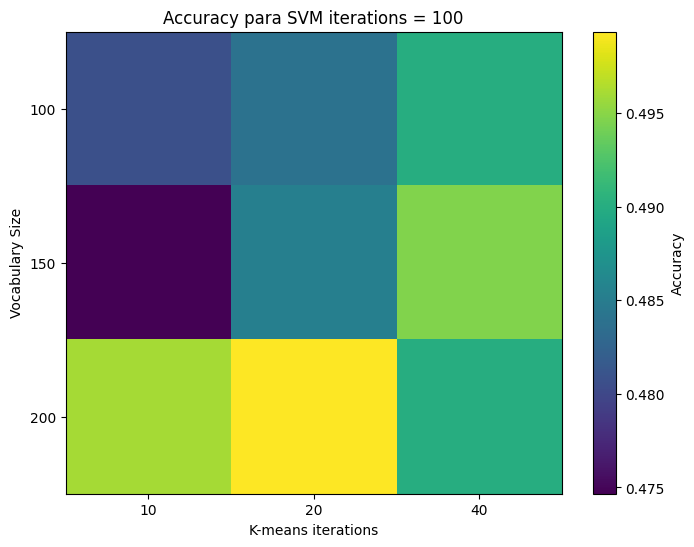

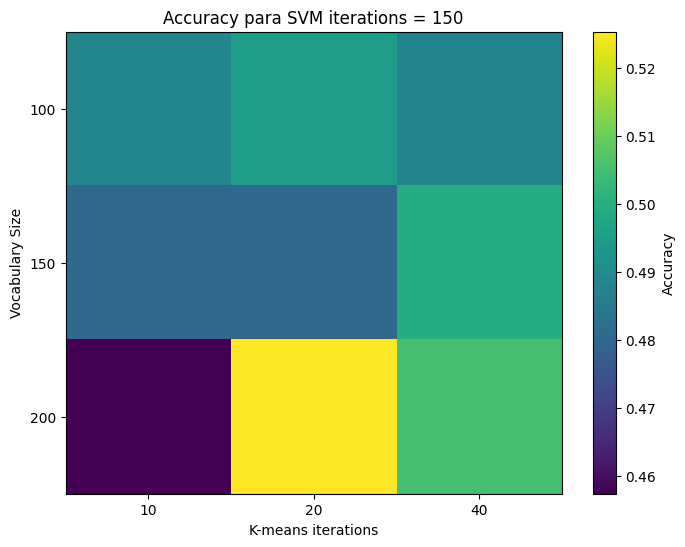

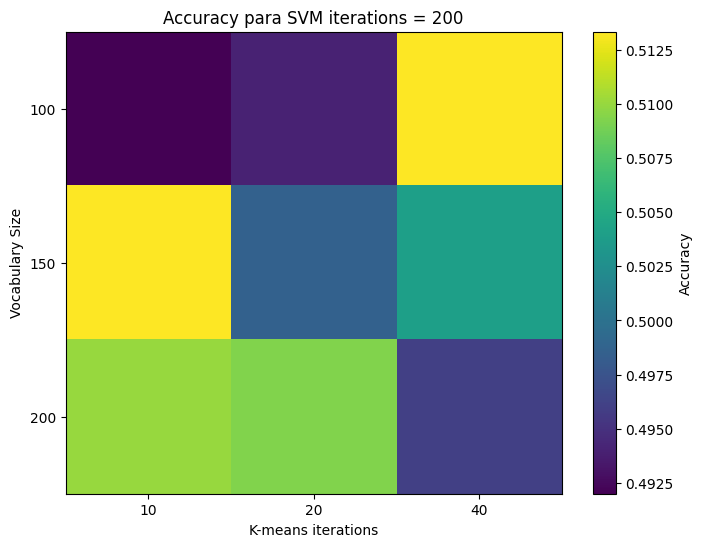

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Valores únicos de los parámetros
vocab_sizes = sorted({r["vocab_size"] for r in results})
kmeans_iters = sorted({r["kmeans_iter"] for r in results})
svm_iters = sorted({r["svm_iter"] for r in results})

for svm_it in svm_iters:

    heatmap = np.zeros((len(vocab_sizes), len(kmeans_iters)))

    for r in results:
        if r["svm_iter"] == svm_it:
            i = vocab_sizes.index(r["vocab_size"])
            j = kmeans_iters.index(r["kmeans_iter"])
            heatmap[i, j] = r["accuracy"]

    plt.figure(figsize=(8,6))
    plt.imshow(heatmap, cmap='viridis', aspect='auto')
    plt.colorbar(label='Accuracy')

    plt.xticks(np.arange(len(kmeans_iters)), kmeans_iters)
    plt.yticks(np.arange(len(vocab_sizes)), vocab_sizes)

    plt.xlabel("K-means iterations")
    plt.ylabel("Vocabulary Size")
    plt.title(f"Accuracy para SVM iterations = {svm_it}")
    plt.show()


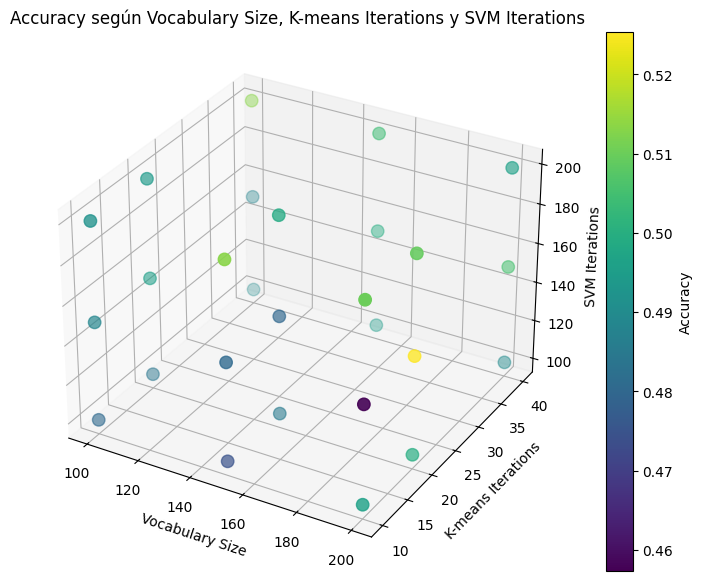

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

xs = [r["vocab_size"] for r in results]
ys = [r["kmeans_iter"] for r in results]
zs = [r["svm_iter"] for r in results]
acc = [r["accuracy"] for r in results]

p = ax.scatter(xs, ys, zs, c=acc, cmap='viridis', s=80)

ax.set_xlabel("Vocabulary Size")
ax.set_ylabel("K-means Iterations")
ax.set_zlabel("SVM Iterations")
fig.colorbar(p, ax=ax, label="Accuracy")

plt.title("Accuracy según Vocabulary Size, K-means Iterations y SVM Iterations")
plt.show()


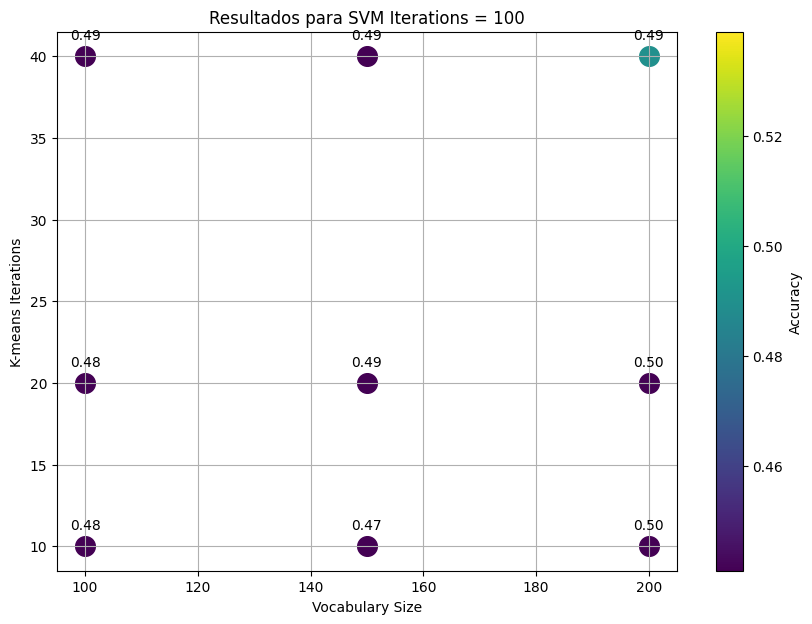

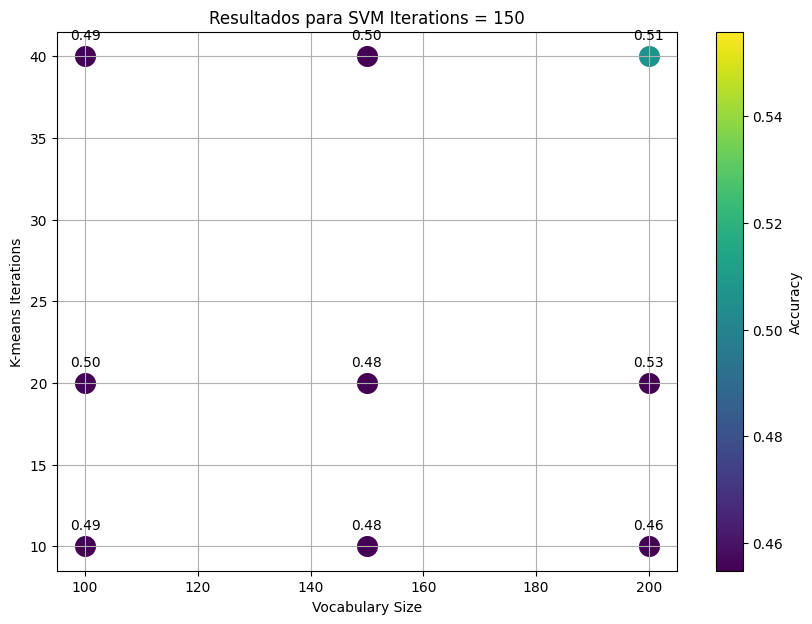

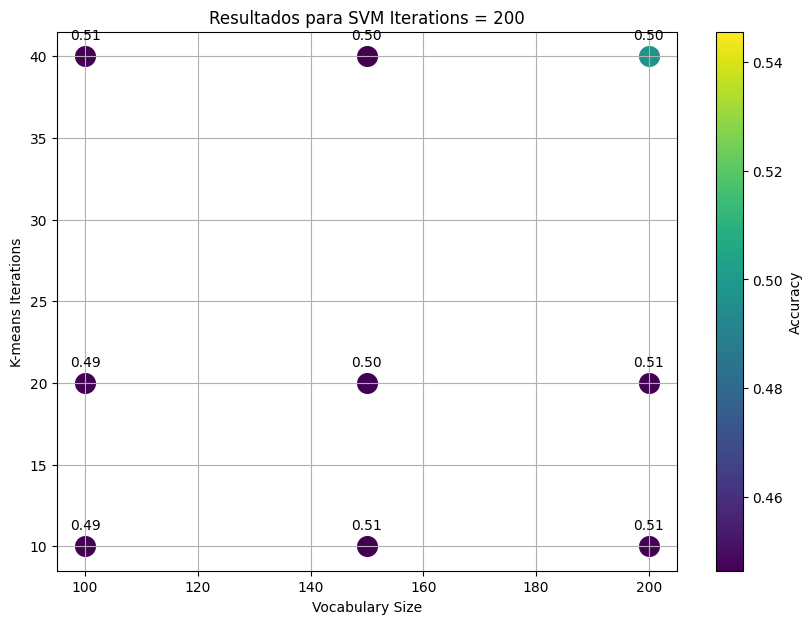

In [ ]:
import matplotlib.pyplot as plt

for svm_it in svm_iters:

    subset = [r for r in results if r["svm_iter"] == svm_it]

    plt.figure(figsize=(10,7))

    for r in subset:
        plt.scatter(r["vocab_size"], r["kmeans_iter"], 
                    c=r["accuracy"], cmap="viridis", s=200)

        plt.text(r["vocab_size"], r["kmeans_iter"] + 1,
                 f"{r['accuracy']:.2f}", ha='center')

    plt.colorbar(label="Accuracy")
    plt.xlabel("Vocabulary Size")
    plt.ylabel("K-means Iterations")
    plt.title(f"Resultados para SVM Iterations = {svm_it}")
    plt.grid(True)
    plt.show()


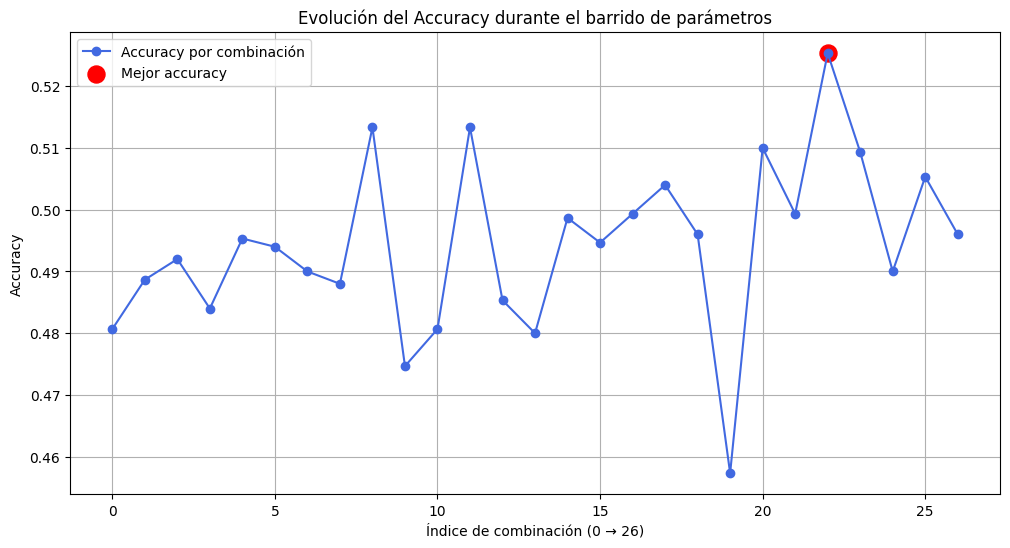

In [ ]:
import matplotlib.pyplot as plt

accs = [r["accuracy"] for r in results]

plt.figure(figsize=(12,6))
plt.plot(accs, marker='o', label="Accuracy por combinación", color='royalblue')

# Marcar el mejor resultado
best_idx = np.argmax(accs)
plt.scatter(best_idx, accs[best_idx], color='red', s=150, label="Mejor accuracy")

plt.title("Evolución del Accuracy durante el barrido de parámetros")
plt.xlabel("Índice de combinación (0 → 26)")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.show()


### Ejecutamos el proceso completo con los parámetros optimizados:

In [ ]:
# MEJOR CONFIGURACIÓN ENCONTRADA:
vocabulary_size = 200
kmeans_iter = 20
svm_iter =  150

output_folder = "../data/partB/optimized_param_results"
os.makedirs(output_folder, exist_ok=True)

print("Extrayendo descriptores del training_set...")
sift = cv2.SIFT_create()
all_descs = []

for path in tqdm(training_set):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    _, desc = sift.detectAndCompute(img, None)
    if desc is not None:
        all_descs.append(desc)

all_descs = np.vstack(all_descs)
print("Total descriptores extraídos:", all_descs.shape)

term_criteria = (
    cv2.TERM_CRITERIA_MAX_ITER | cv2.TERM_CRITERIA_EPS,
    kmeans_iter,
    1e-6
)

bow_trainer = cv2.BOWKMeansTrainer(vocabulary_size, term_criteria)
bow_trainer.add(all_descs)

vocabulary = bow_trainer.cluster()

with open(f"{output_folder}/optimized_vocab.pickle", "wb") as f:
    pickle.dump(["SIFT", vocabulary], f)

###################################################################
# 3.2 ENTRENAR SVM SOBRE EL TRAINING SET
###################################################################

bow_train = BoW()
bow_train.load_vocabulary(filename=f"{output_folder}/optimized_vocab")

classifier_train = ImageClassifier(bow_train)
classifier_train.train(training_set=training_set,
                        iterations=svm_iter) 

classifier_train.save(f"{output_folder}/optimized_classifier")

###################################################################
# 3.3 VALIDACIÓN (PREDICT) SOBRE validation_set
###################################################################

bow_val = BoW()
bow_val.load_vocabulary(filename=f"{output_folder}/optimized_vocab")

classifier_val = ImageClassifier(bow_val)
classifier_val.load(f"{output_folder}/optimized_classifier")

accuracy, confusion_matrix, classification = classifier_val.predict(
    dataset=validation_set,
    dataset_name=f"{output_folder}/v{vocabulary_size}_k{kmeans_iter}_s{svm_iter}"
)

print(f">> Accuracy obtenida con los parámetros optimizados = {accuracy:.4f}")


Extrayendo descriptores del training_set...


100%|██████████| 2981/2981 [01:37<00:00, 30.69it/s]


Total descriptores extraídos: (1537657, 128)


TRAINING CLASSIFIER

Extracting features...
100%|██████████| 2981/2981 [01:54<00:00, 26.13image/s]

Training SVM...


CLASSIFICATION RESULTS (../DATA/PARTB/OPTIMIZED_PARAM_RESULTS/V200_K20_S150)

Confusion matrix

KNOWN/PREDICTED  Bedroom  Coast  Forest  Highway  Industrial  Inside city  Kitchen  Living room  Mountain  Office  Open country  Store  Street  Suburb  Tall building
Bedroom             21.0    3.0     1.0      2.0        10.0          8.0      9.0         21.0       0.0     7.0           0.0    8.0     3.0     2.0            5.0
Coast                4.0   49.0     1.0     12.0         3.0          1.0      0.0          0.0       9.0     0.0          20.0    0.0     0.0     0.0            1.0
Forest               0.0    4.0    90.0      0.0         0.0          0.0      0.0          0.0       3.0     0.0           3.0    0.0     0.0     0.0            0.0
Highway              1.0   23.0     0.0     42.0         6.0          6.0  